# Predicting total spend

Goal: predict `total_spend` for newer campaigns. CPE is a fixed price per product, so it is trivial to predict and is not modeled here.

## 1. Load the data

`target_list` (doctors the campaign plans to target) and `campaign_size` (planned size tier) come from the second data file.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

root = Path.cwd()
if not (root / "data" / "cleaned_df.csv").exists():
    root = root.parent

df = pd.read_csv(root / "data" / "cleaned_df.csv")
df["campaign_start_date"] = pd.to_datetime(df["campaign_start_date"])

# Add target_list and campaign_size from the second data file, matched on campaign outcome columns
key = ["unique_reach", "total_engagements", "total_budget_spent", "total_spend"]
extra = pd.read_excel(root / "data" / "BreakThroughTech_training_data_2.xlsx", usecols=key + ["target_list", "campaign_size"])
df = df.merge(extra, on=key, how="left", validate="one_to_one")
assert df[["target_list", "campaign_size"]].notna().all().all()

print("Rows:", len(df))
df[["company", "sub_product_name", "campaign_start_date", "target_list", "campaign_size", "total_spend"]].head()

Rows: 414


,company,sub_product_name,campaign_start_date,target_list,campaign_size,total_spend
0,ABBVIE,BRAND ALERT,2024-07-31,17694,Large,134355308.0
1,ABBVIE,BRAND ALERT,2024-08-19,4855,Medium,10667850.0
2,ABBVIE,BRAND ALERT,2023-11-16,5285,Medium,59103000.0
3,ABBVIE,BRAND ALERT,2024-11-22,13926,Medium,124487739.0
4,ABBVIE,EMAIL ALERT,2023-11-16,159257,Large,892409925.0


## 2. Split by start date

Oldest 80% for training, newest 20% for validation.

In [2]:
cutoff = df["campaign_start_date"].quantile(0.80)
train = df[df["campaign_start_date"] <= cutoff].copy()
val = df[df["campaign_start_date"] > cutoff].copy()

assert train["campaign_start_date"].max() < val["campaign_start_date"].min()
print("Training rows:", len(train))
print("Validation rows:", len(val))

Training rows: 332
Validation rows: 82


## 3. Look at total spend

Spend ranges from 0 to tens of billions, so we also view it on a log scale.

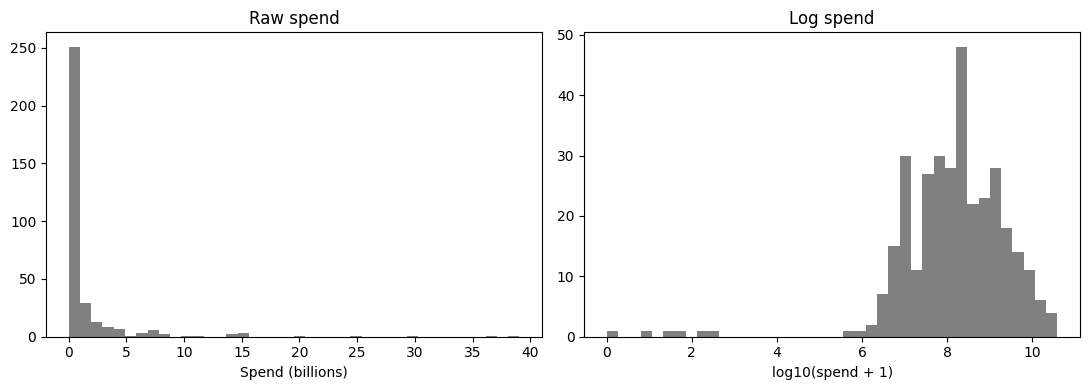

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train["total_spend"] / 1e9, bins=40, color="gray")
axes[0].set_title("Raw spend")
axes[0].set_xlabel("Spend (billions)")
axes[1].hist(np.log10(train["total_spend"] + 1), bins=40, color="gray")
axes[1].set_title("Log spend")
axes[1].set_xlabel("log10(spend + 1)")
plt.tight_layout()
plt.show()

### Correlation with other numeric columns

Spearman correlation on training rows. Columns calculated from spend are left out.

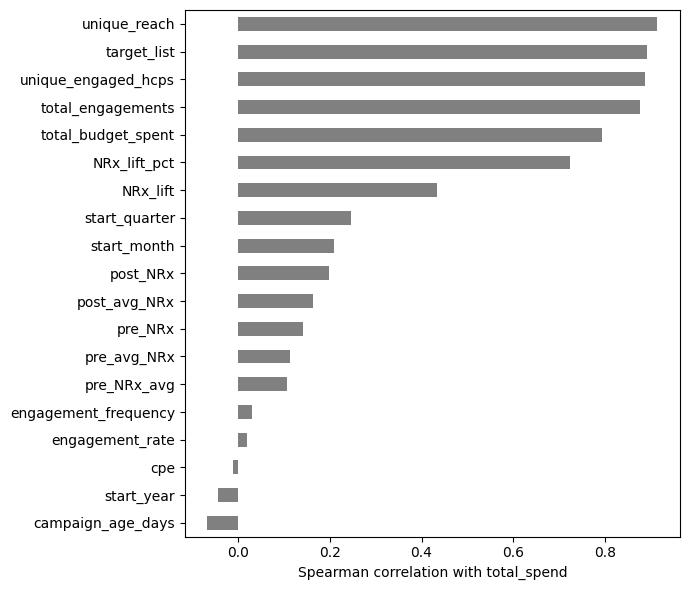

unique_reach            0.91
target_list             0.89
unique_engaged_hcps     0.89
total_engagements       0.87
total_budget_spent      0.79
NRx_lift_pct            0.72
NRx_lift                0.43
start_quarter           0.25
start_month             0.21
post_NRx                0.20
post_avg_NRx            0.16
pre_NRx                 0.14
pre_avg_NRx             0.11
pre_NRx_avg             0.11
engagement_frequency    0.03
engagement_rate         0.02
cpe                    -0.01
start_year             -0.04
campaign_age_days      -0.07
Name: total_spend, dtype: float64

In [4]:
derived_from_spend = ["actual_spend_per_engagement", "spend_per_NRx_lift"]
flags = ["cpe_imputed", "spend_near_zero", "budget_anomaly", "targeting_info_missing"]
numeric = train.select_dtypes("number").drop(columns=derived_from_spend + flags)

correlation = numeric.corr(method="spearman")["total_spend"].drop("total_spend").sort_values()
correlation.plot.barh(figsize=(7, 6), color="gray")
plt.xlabel("Spearman correlation with total_spend")
plt.tight_layout()
plt.show()
correlation.sort_values(ascending=False).round(2)

## 4. Baselines

Two simple guesses learned from training rows: the overall median spend, and the median spend for each product.

In [5]:
overall_median = train["total_spend"].median()
product_median = train.groupby("sub_product_name")["total_spend"].median()

baselines = pd.DataFrame({
    "overall median": overall_median,
    "product median": val["sub_product_name"].map(product_median).fillna(overall_median)
}, index=val.index)

product_median.sort_values().map("{:,.0f}".format)

sub_product_name
CONDITION MESSAGE              0
DIRECT MAIL            8,624,000
BRAND INTERCEPT        9,395,160
BRAND ALERT           98,115,863
BRAND PLAY           126,123,118
BRANDSTORY           160,110,366
EMAIL ALERT          184,500,000
BRANDSPOT            186,036,222
INFOSITE             265,894,695
POINT OF CONTACT     520,229,546
TARGET LIST MEDIA    826,607,844
Name: total_spend, dtype: object

### Score

MAPE uses validation rows with spend of at least 1,000. "Typical factor off" is how many times too high or too low the median prediction is.

In [6]:
y_val = val["total_spend"]

def score(predictions):
    scored = y_val >= 1000
    rows = []
    for name in predictions:
        pred = predictions[name]
        pct_error = (y_val - pred).abs()[scored] / y_val[scored]
        factor_off = np.maximum(pred[scored] / y_val[scored], y_val[scored] / pred[scored])
        rows.append({
            "model": name,
            "R2": r2_score(y_val, pred),
            "log R2": r2_score(np.log1p(y_val), np.log1p(pred.clip(lower=0))),
            "MAPE (%)": pct_error.mean() * 100,
            "typical factor off": factor_off.median(),
            "within 2x (%)": (factor_off <= 2).mean() * 100
        })
    return pd.DataFrame(rows).set_index("model").round(2)

score(baselines)

,R2,log R2,MAPE (%),typical factor off,within 2x (%)
model,,,,,
overall median,-0.14,-0.07,766.68,5.13,16.25
product median,-0.13,-0.02,693.83,5.15,20.00


## 5. Choose inputs

Only columns known when a campaign is planned, including `campaign_size` and the log of `target_list`. Each category becomes 0/1 columns, using categories seen in training.

In [7]:
category_columns = ["company", "sub_product_name", "country", "npi_specialty", "region", "campaign_size"]

def make_inputs(rows):
    X = rows[category_columns].copy()
    for column in category_columns:
        X[column] = pd.Categorical(rows[column], categories=sorted(train[column].unique()))
    X["start_year"] = rows["campaign_start_date"].dt.year
    X["start_month"] = rows["campaign_start_date"].dt.month
    X["log_target_list"] = np.log1p(rows["target_list"])
    return pd.get_dummies(X, drop_first=True, dtype=int)

X_train = make_inputs(train)
X_val = make_inputs(val)
log_y_train = np.log1p(train["total_spend"])

print("Input columns:", X_train.shape[1])
print("Validation rows with a category not seen in training:")
print(val[category_columns].apply(lambda c: (~c.isin(train[c.name])).sum()))

Input columns: 72
Validation rows with a category not seen in training:
company             6
sub_product_name    0
country             0
npi_specialty       1
region              0
campaign_size       0
dtype: int64


### Save the split

For teammates building their own spend models. `y` is raw `total_spend`; take `np.log1p` to model log spend.

In [8]:
out = root / "data" / "spend_train_val_split"
out.mkdir(exist_ok=True)
X_train.to_csv(out / "X_train.csv", index=False)
X_val.to_csv(out / "X_val.csv", index=False)
train[["total_spend"]].to_csv(out / "y_train.csv", index=False)
val[["total_spend"]].to_csv(out / "y_val.csv", index=False)
print("Saved to", out.relative_to(root), "-", X_train.shape, X_val.shape)

Saved to data/spend_train_val_split - (332, 72) (82, 72)


## 6. Linear regression

Ridge regression on log spend. Inputs are scaled so the penalty treats them equally, and the penalty strength is picked by cross-validation on training rows.

In [9]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))

# Group the 72 columns back into the inputs they came from
input_groups = {"target_list": ["log_target_list"], "date": ["start_year", "start_month"]}
for column in category_columns:
    input_groups[column] = [c for c in X_train.columns if c.startswith(column + "_")]

### Which inputs to use

Each input set is scored with time-ordered cross-validation on training rows only (train on older campaigns, test on later ones), so the validation set is not used to choose.

In [10]:
by_date = train.sort_values("campaign_start_date").index
candidates = {
    "target_list": ["target_list"],
    "+ product": ["target_list", "sub_product_name"],
    "+ product, size": ["target_list", "sub_product_name", "campaign_size"],
    "+ product, size, company": ["target_list", "sub_product_name", "campaign_size", "company"],
    "+ product, size, company, date": ["target_list", "sub_product_name", "campaign_size", "company", "date"],
    "all inputs": list(input_groups)
}

rows = []
for name, groups in candidates.items():
    columns = sum((input_groups[g] for g in groups), [])
    cv = cross_val_score(ridge(), X_train.loc[by_date, columns], log_y_train[by_date], cv=TimeSeriesSplit(5), scoring="r2")
    rows.append({"inputs": name, "columns": len(columns), "CV log R2": cv.mean()})
pd.DataFrame(rows).set_index("inputs").round(2)

/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/Web

/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encou

/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encou

,columns,CV log R2
inputs,,
target_list,1,0.48
+ product,11,0.44
"+ product, size",14,0.48
"+ product, size, company",42,0.43
"+ product, size, company, date",44,0.33
all inputs,72,0.31


### Final model

`target_list`, product and campaign size tie for the best cross-validation score using only 14 columns. Adding more inputs makes it worse.

In [11]:
chosen = sum((input_groups[g] for g in ["target_list", "sub_product_name", "campaign_size"]), [])
model = ridge().fit(X_train[chosen], log_y_train)
print("Columns used:", len(chosen))
print("Chosen penalty (alpha):", round(model[-1].alpha_, 2))

Columns used: 14
Chosen penalty (alpha): 8.53


/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


### Score

Predictions are converted back from log spend to spend, then compared with the baselines.

In [12]:
predictions = baselines.copy()
predictions["ridge regression"] = np.expm1(model.predict(X_val[chosen])).clip(min=0)
score(predictions)

/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/abhiramsegu/Desktop/WebMd/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,R2,log R2,MAPE (%),typical factor off,within 2x (%)
model,,,,,
overall median,-0.14,-0.07,766.68,5.13,16.25
product median,-0.13,-0.02,693.83,5.15,20.00
ridge regression,0.42,0.38,106.50,1.99,50.00


### Predicted vs actual

Points on the dashed line are perfect predictions.

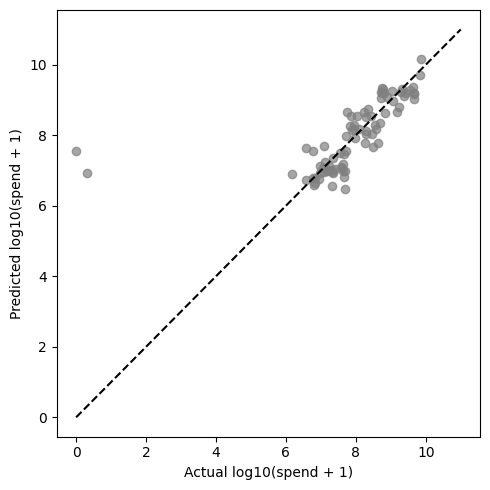

In [13]:
plt.figure(figsize=(5, 5))
plt.scatter(np.log10(y_val + 1), np.log10(predictions["ridge regression"] + 1), color="gray", alpha=0.7)
plt.plot([0, 11], [0, 11], "k--")
plt.xlabel("Actual log10(spend + 1)")
plt.ylabel("Predicted log10(spend + 1)")
plt.tight_layout()
plt.show()